# Impact-sensitivity classification evaluation

This notebook evaluates the current binary, tertiary, quaternary, and quinary workflow. It discovers partial HPC results, reports missing tasks, aggregates held-out metrics only across completed seeds, inspects class-level behaviour, and exports reusable tables.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import auc, roc_curve
from sklearn.preprocessing import label_binarize

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / '08_CLASSIFICATION').is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError('Could not locate the repository root.')
    PROJECT_ROOT = PROJECT_ROOT.parent

CLASSIFICATION_DIR = PROJECT_ROOT / '08_CLASSIFICATION'
sys.path.insert(0, str(CLASSIFICATION_DIR))
from classification_evaluation import (
    CLASSIFICATIONS, EMBEDDINGS, MODELS, SEEDS, aggregate_runs,
    completion_table, discover_runs, export_tables, load_predictions,
    normalised_confusion_matrix, per_class_metrics,
)

RESULT_DATE = '20260805'  # Change this to evaluate another batch
RESULTS_ROOT = PROJECT_ROOT / '07_OUTPUTS' / RESULT_DATE / 'IS_classification'
DATASET_PATH = CLASSIFICATION_DIR / '01_DATASETS' / 'combined_IS_dataset.csv'
EMBEDDINGS_DIR = CLASSIFICATION_DIR / '02_EMBEDDINGS'
EXPORT_DIR = PROJECT_ROOT / '07_OUTPUTS' / RESULT_DATE / 'classification_evaluation'

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 100)
print(f'Results: {RESULTS_ROOT}')

Results: /home/andre/fm-4-em/07_OUTPUTS/20260805/IS_classification


## 1. Validate current data and embeddings

In [2]:
classification_df = pd.read_csv(DATASET_PATH)
missing_targets = set(CLASSIFICATIONS).difference(classification_df.columns)
if missing_targets:
    raise KeyError(f'Missing classification columns: {sorted(missing_targets)}')

embedding_rows = []
embedding_paths = {}
for embedding in EMBEDDINGS:
    path = EMBEDDINGS_DIR / f'{embedding}_embeddings.npy'
    matrix = np.load(path, mmap_mode='r')
    embedding_paths[embedding] = path
    embedding_rows.append({
        'embedding': embedding, 'rows': matrix.shape[0],
        'dimensions': matrix.shape[1] if matrix.ndim == 2 else np.nan,
        'dtype': str(matrix.dtype), 'aligned': matrix.shape[0] == len(classification_df),
    })
embedding_summary = pd.DataFrame(embedding_rows)
if not embedding_summary['aligned'].all():
    raise ValueError('At least one embedding is not aligned with the dataset.')

class_counts = pd.concat(
    [classification_df[name].value_counts().sort_index().rename(name) for name in CLASSIFICATIONS],
    axis=1,
).T
display(embedding_summary)
display(class_counts.style.format('{:.0f}', na_rep=''))

,embedding,rows,dimensions,dtype,aligned
0,hq_descriptor,980,17,float64,True
1,chemeleon,980,2048,float32,True
2,morgan_fps,980,2048,int64,True
3,maceoff_large,980,448,float64,True
4,molclr,980,512,float64,True


,0,1,2,3,4
binary,392,588,,,
tertiary,323,311,346,,
quaternary,235,257,255,233,
quinary,179,213,208,308,72


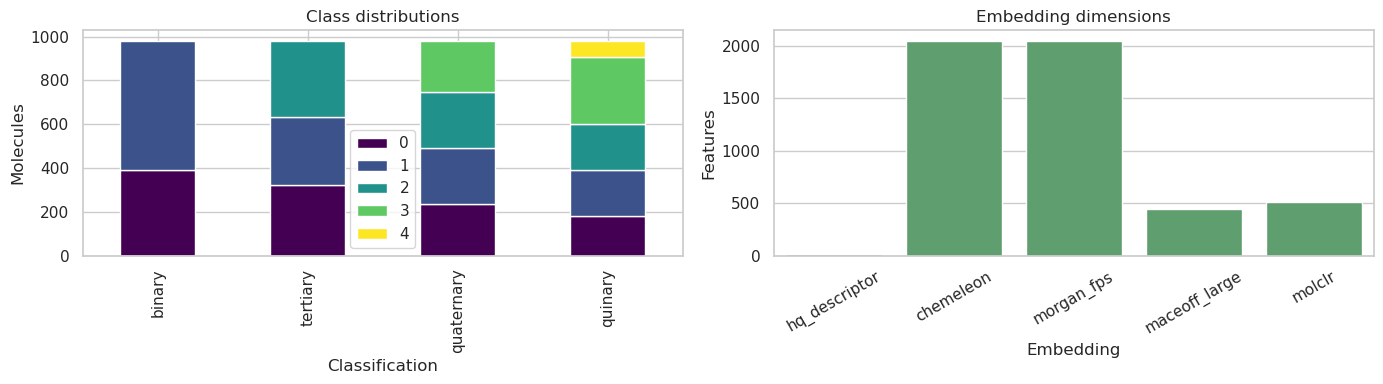

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
class_counts.plot(kind='bar', stacked=True, ax=axes[0], colormap='viridis')
axes[0].set(title='Class distributions', xlabel='Classification', ylabel='Molecules')
sns.barplot(data=embedding_summary, x='embedding', y='dimensions', ax=axes[1], color='#55A868')
axes[1].set(title='Embedding dimensions', xlabel='Embedding', ylabel='Features')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

## 2. Discover completed and missing runs

The full design contains 600 tasks: 4 classifications × 6 models × 5 embeddings × 5 seeds. Partial batches are valid; missing combinations are never imputed.

In [4]:
runs, rejected_summaries = discover_runs(RESULTS_ROOT)
completion, missing_runs = completion_table(runs)
print(f'Completed unique runs: {len(runs)} / {len(completion)}')
print(f'Missing runs: {len(missing_runs)}; rejected summaries: {len(rejected_summaries)}')
display(runs.head())
if not rejected_summaries.empty:
    display(rejected_summaries)

Completed unique runs: 500 / 600
Missing runs: 100; rejected summaries: 0


,classification,n_classes,model,embedding,seed,embedding_dim,test_size,cv_splits,n_train,n_test,best_cv_score,best_params,train_accuracy,train_balanced_accuracy,train_f1_macro,train_roc_auc,test_accuracy,test_balanced_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_f1_weighted,test_roc_auc,roc_auc_error,test_confusion_matrix,test_classification_report,duration_seconds,started_at,finished_at,run_dir,summary_path
0,binary,2,bayes,chemeleon,0,2048,0.2,3,784,196,0.668631,"{""classifier__var_smoothing"": 3.16227766016837...",0.679847,0.709724,0.679821,0.773072,0.704082,0.721643,0.713836,0.721643,0.702968,0.706680,0.778031,None,"[[63, 15], [43, 75]]","{'0': {'precision': 0.5943396226415094, 'recal...",1.368848,2026-08-05T11:44:00.215215,2026-08-05 11:44:01.584063,/home/andre/fm-4-em/07_OUTPUTS/20260805/IS_cla...,/home/andre/fm-4-em/07_OUTPUTS/20260805/IS_cla...
1,binary,2,bayes,chemeleon,1,2048,0.2,3,784,196,0.688596,"{""classifier__var_smoothing"": 3.16227766016837...",0.686224,0.708172,0.685930,0.767929,0.663265,0.683399,0.678436,0.683399,0.662703,0.665513,0.726749,None,"[[61, 17], [49, 69]]","{'0': {'precision': 0.5545454545454546, 'recal...",2.310751,2026-08-05T11:45:46.901795,2026-08-05 11:45:49.212546,/home/andre/fm-4-em/07_OUTPUTS/20260805/IS_cla...,/home/andre/fm-4-em/07_OUTPUTS/20260805/IS_cla...
2,binary,2,bayes,chemeleon,2,2048,0.2,3,784,196,0.703699,"{""classifier__var_smoothing"": 1e-06}",0.693878,0.717197,0.693678,0.771795,0.642857,0.664276,0.660714,0.664276,0.642522,0.644755,0.731095,None,"[[60, 18], [52, 66]]","{'0': {'precision': 0.5357142857142857, 'recal...",1.537356,2026-08-05T11:47:31.063539,2026-08-05 11:47:32.600895,/home/andre/fm-4-em/07_OUTPUTS/20260805/IS_cla...,/home/andre/fm-4-em/07_OUTPUTS/20260805/IS_cla...
3,binary,2,bayes,chemeleon,3,2048,0.2,3,784,196,0.669542,"{""classifier__var_smoothing"": 1e-06}",0.705357,0.732586,0.705334,0.785042,0.658163,0.681334,0.677951,0.681334,0.657941,0.659721,0.720448,None,"[[62, 16], [51, 67]]","{'0': {'precision': 0.5486725663716814, 'recal...",2.044048,2026-08-05T11:48:46.892692,2026-08-05 11:48:48.936740,/home/andre/fm-4-em/07_OUTPUTS/20260805/IS_cla...,/home/andre/fm-4-em/07_OUTPUTS/20260805/IS_cla...
4,binary,2,bayes,chemeleon,4,2048,0.2,3,784,196,0.673817,"{""classifier__var_smoothing"": 3.16227766016837...",0.668367,0.697506,0.668348,0.762495,0.709184,0.721534,0.712507,0.721534,0.706979,0.712166,0.742992,None,"[[61, 17], [40, 78]]","{'0': {'precision': 0.6039603960396039, 'recal...",1.525958,2026-08-05T11:49:31.159160,2026-08-05 11:49:32.685118,/home/andre/fm-4-em/07_OUTPUTS/20260805/IS_cla...,/home/andre/fm-4-em/07_OUTPUTS/20260805/IS_cla...


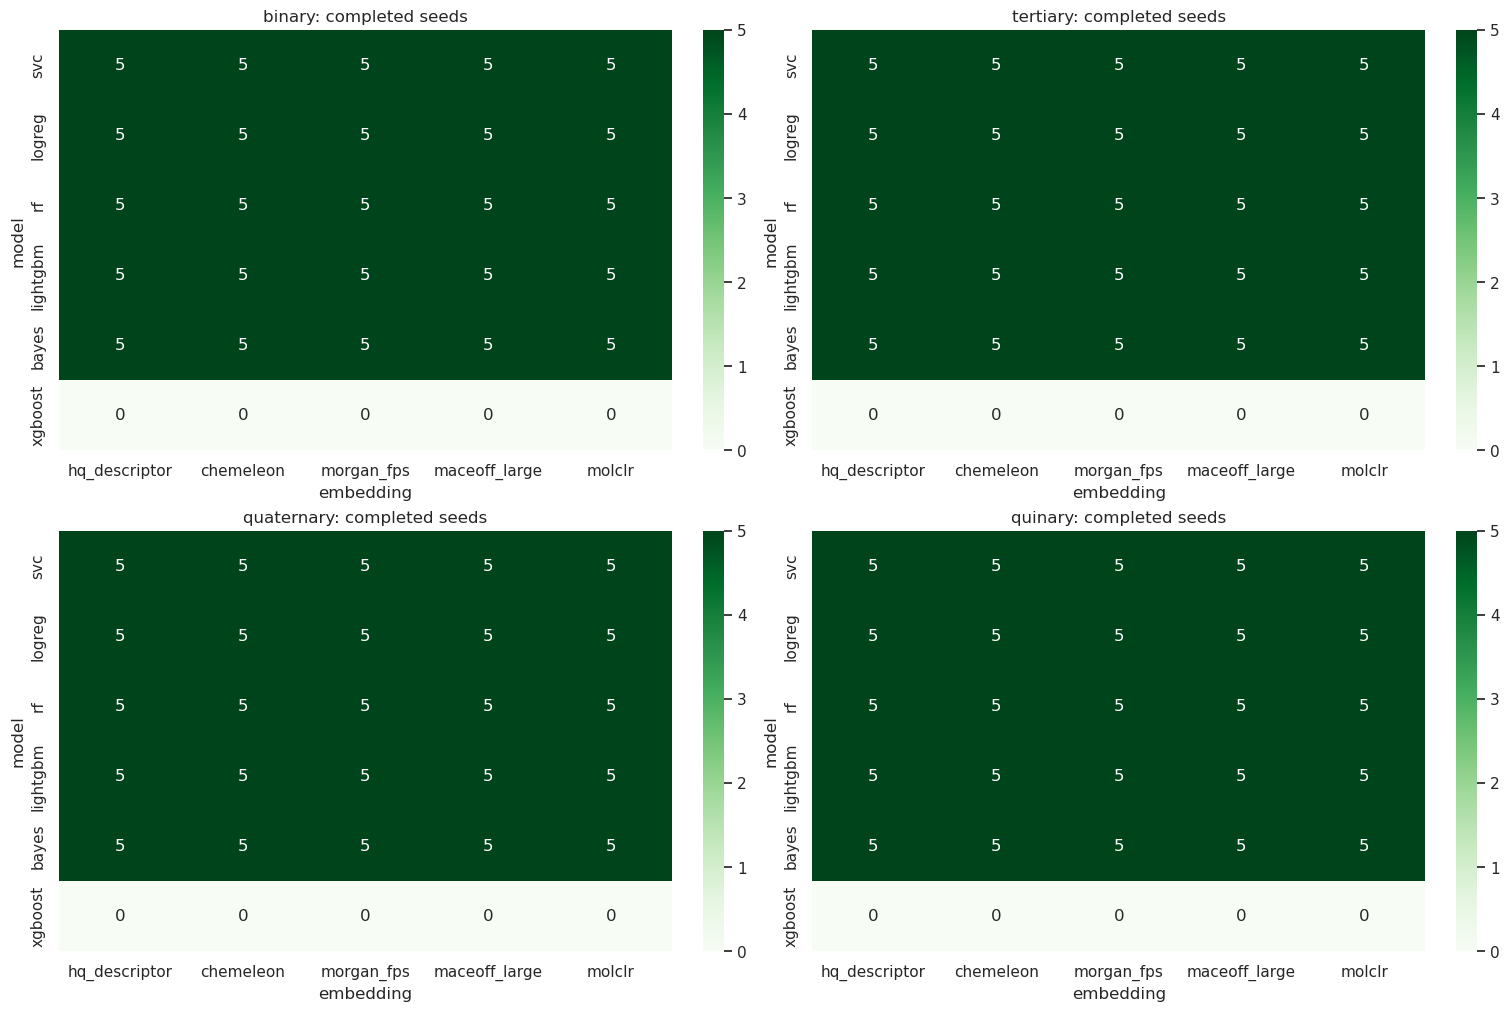

,classification,model,embedding,seed
0,binary,xgboost,hq_descriptor,0
1,binary,xgboost,hq_descriptor,1
2,binary,xgboost,hq_descriptor,2
3,binary,xgboost,hq_descriptor,3
4,binary,xgboost,hq_descriptor,4
5,binary,xgboost,chemeleon,0
6,binary,xgboost,chemeleon,1
7,binary,xgboost,chemeleon,2
8,binary,xgboost,chemeleon,3
9,binary,xgboost,chemeleon,4


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
for axis, classification in zip(axes.flat, CLASSIFICATIONS):
    matrix = (completion.loc[completion['classification'].eq(classification)]
              .pivot_table(index='model', columns='embedding', values='completed', aggfunc='sum')
              .reindex(index=MODELS, columns=EMBEDDINGS))
    sns.heatmap(matrix, annot=True, fmt='.0f', cmap='Greens', vmin=0, vmax=len(SEEDS), ax=axis)
    axis.set_title(f'{classification}: completed seeds')
plt.show()
display(missing_runs.head(30))

## 3. Held-out performance across available seeds

In [6]:
aggregate_results = aggregate_runs(runs)
display(aggregate_results.style.format({
    'balanced_accuracy_mean': '{:.3f}', 'balanced_accuracy_std': '{:.3f}',
    'accuracy_mean': '{:.3f}', 'f1_macro_mean': '{:.3f}',
    'roc_auc_mean': '{:.3f}', 'generalisation_gap_mean': '{:.3f}',
    'duration_seconds_mean': '{:.1f}',
}, na_rep='—'))

,classification,model,embedding,seeds_completed,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,roc_auc_mean,roc_auc_std,generalisation_gap_mean,duration_seconds_mean
0,binary,lightgbm,chemeleon,5,0.844,0.037,0.855,0.039946,0.847,0.040953,0.924,0.030269,0.156,350.4
1,binary,rf,maceoff_large,5,0.840,0.023,0.851,0.026363,0.843,0.026115,0.917,0.023911,0.134,150.7
2,binary,lightgbm,maceoff_large,5,0.838,0.018,0.849,0.022122,0.841,0.021447,0.917,0.023409,0.157,149.2
3,binary,rf,chemeleon,5,0.835,0.029,0.851,0.027805,0.841,0.029699,0.920,0.027821,0.148,323.3
4,binary,rf,molclr,5,0.821,0.019,0.835,0.020912,0.825,0.020906,0.897,0.011455,0.164,133.8
5,binary,logreg,maceoff_large,5,0.813,0.029,0.815,0.026609,0.809,0.027821,0.875,0.027555,0.016,10.7
6,binary,lightgbm,molclr,5,0.813,0.028,0.827,0.024469,0.816,0.026843,0.895,0.017047,0.186,142.5
7,binary,lightgbm,hq_descriptor,5,0.811,0.041,0.826,0.038587,0.815,0.041856,0.885,0.033639,0.146,72.0
8,binary,rf,hq_descriptor,5,0.808,0.037,0.824,0.031780,0.813,0.036074,0.897,0.031551,0.143,32.1
9,binary,svc,maceoff_large,5,0.807,0.017,0.812,0.013206,0.805,0.013748,0.870,0.019065,0.017,118.9


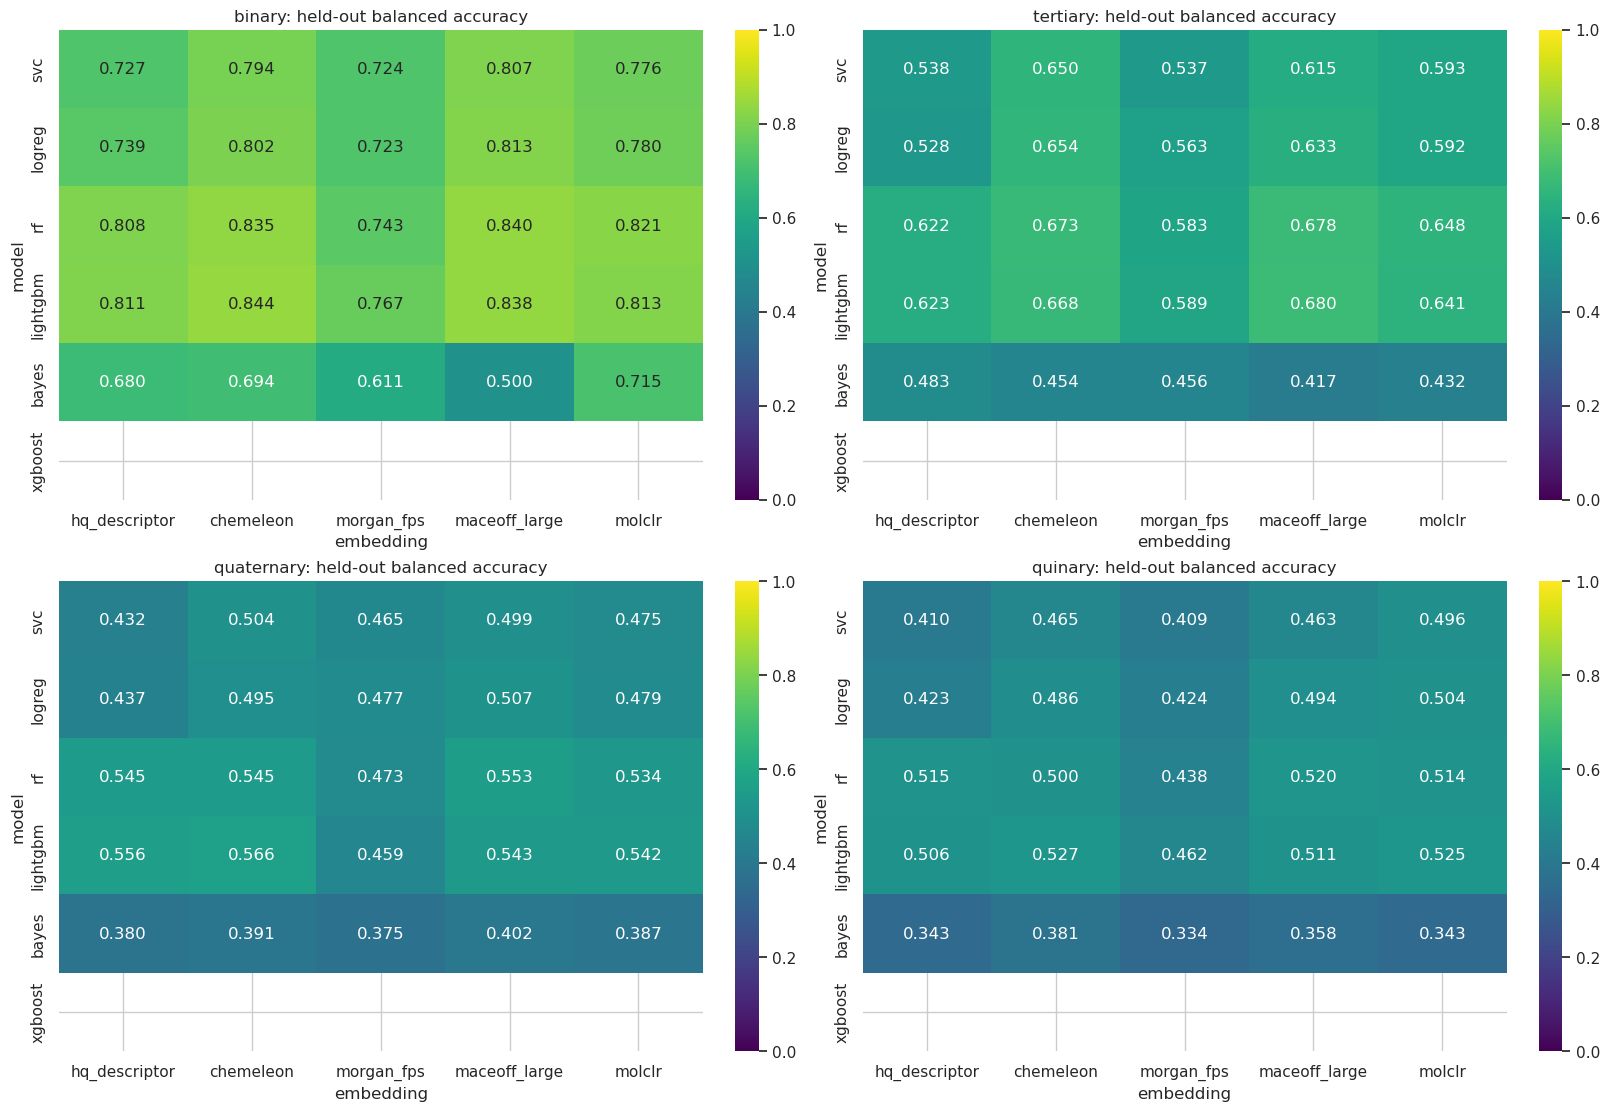

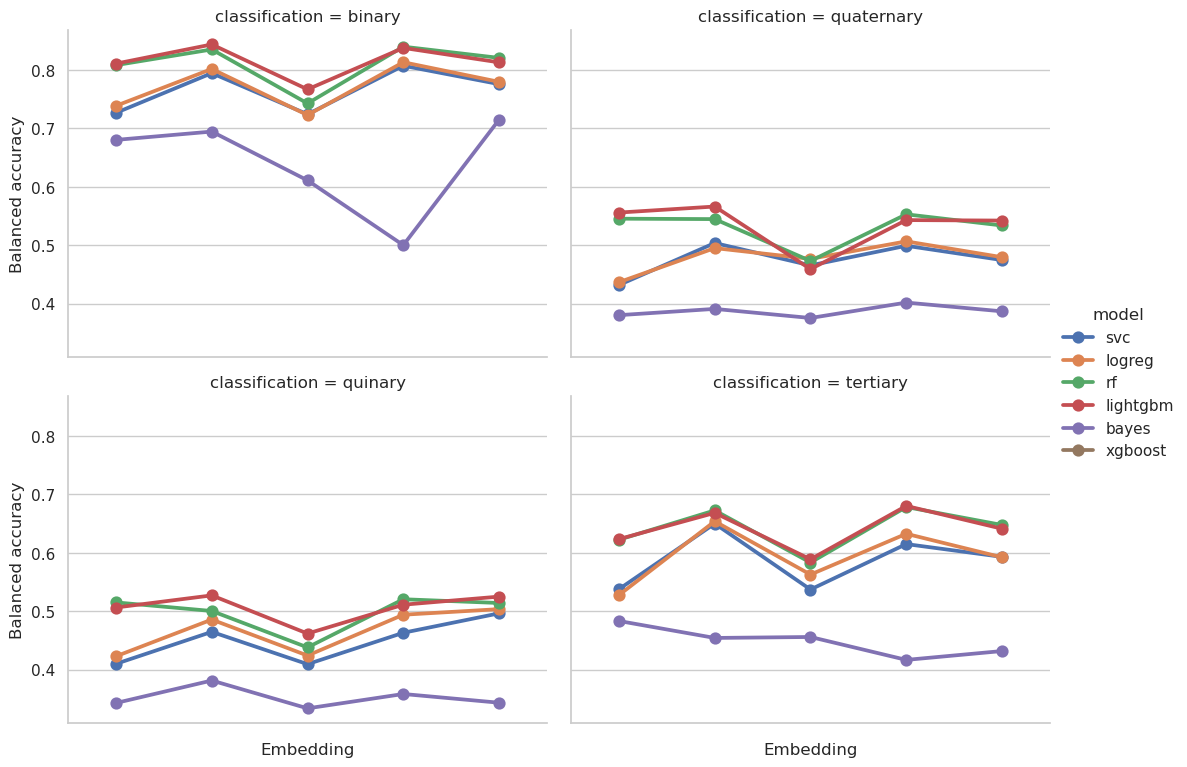

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)
for axis, classification in zip(axes.flat, CLASSIFICATIONS):
    subset = aggregate_results.loc[aggregate_results['classification'].eq(classification)]
    matrix = subset.pivot(index='model', columns='embedding', values='balanced_accuracy_mean')
    matrix = matrix.reindex(index=MODELS, columns=EMBEDDINGS)
    sns.heatmap(matrix, annot=True, fmt='.3f', cmap='viridis', vmin=0, vmax=1, ax=axis)
    axis.set_title(f'{classification}: held-out balanced accuracy')
plt.show()

g = sns.catplot(
    data=runs, x='embedding', y='test_balanced_accuracy', hue='model',
    col='classification', col_wrap=2, kind='point', errorbar=None,
    order=EMBEDDINGS, hue_order=MODELS, height=4, aspect=1.35,
)
g.set_xticklabels(rotation=30); g.set_axis_labels('Embedding', 'Balanced accuracy')
plt.show()

## 4. Class-level performance and confusion matrices

,classification,model,embedding,class_label,seeds,precision,recall,f1,support
4,binary,bayes,maceoff_large,0,5,0.000000,0.000000,0.000000,390
8,binary,bayes,morgan_fps,0,5,0.520016,0.574359,0.545046,390
2,binary,bayes,hq_descriptor,0,5,0.679375,0.528205,0.592537,390
0,binary,bayes,chemeleon,0,5,0.567446,0.787179,0.659215,390
6,binary,bayes,molclr,0,5,0.637867,0.692308,0.662789,390
28,binary,logreg,morgan_fps,0,5,0.678402,0.648718,0.662970,390
48,binary,svc,morgan_fps,0,5,0.669239,0.666667,0.667440,390
42,binary,svc,hq_descriptor,0,5,0.679992,0.661538,0.669488,390
9,binary,bayes,morgan_fps,1,5,0.696827,0.647458,0.670612,590
38,binary,rf,morgan_fps,0,5,0.720187,0.656410,0.685885,390


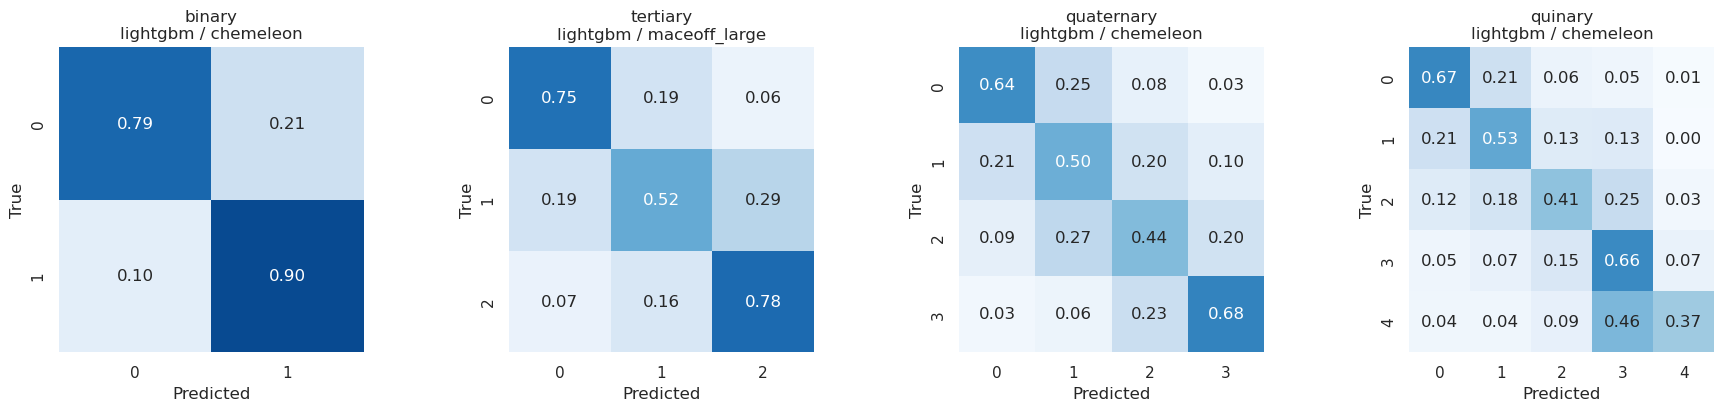

In [8]:
class_metrics = per_class_metrics(runs)
class_metric_summary = (class_metrics
    .groupby(['classification', 'model', 'embedding', 'class_label'], as_index=False)
    .agg(seeds=('seed', 'nunique'), precision=('precision', 'mean'),
         recall=('recall', 'mean'), f1=('f1', 'mean'), support=('support', 'sum')))
display(class_metric_summary.sort_values(['classification', 'f1']).head(30))

best_rows = (aggregate_results.sort_values('balanced_accuracy_mean', ascending=False)
             .drop_duplicates('classification').set_index('classification'))
fig, axes = plt.subplots(1, 4, figsize=(18, 4), constrained_layout=True)
for axis, classification in zip(axes, CLASSIFICATIONS):
    if classification not in best_rows.index:
        axis.set_visible(False); continue
    best = best_rows.loc[classification]
    subset = runs.loc[(runs['classification'] == classification) &
                      (runs['model'] == best['model']) &
                      (runs['embedding'] == best['embedding'])]
    n_classes = int(subset['n_classes'].dropna().iloc[0])
    matrix = normalised_confusion_matrix(subset, n_classes)
    sns.heatmap(matrix, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
                square=True, cbar=False, ax=axis)
    axis.set(title=f"{classification}\n{best['model']} / {best['embedding']}",
             xlabel='Predicted', ylabel='True')
plt.show()

## 5. ROC curves for one selected run

This supports binary ROC and multiclass one-vs-rest ROC. Edit the selections; the first available seed is used.

/home/andre/anaconda3/envs/chem/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.2.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/andre/anaconda3/envs/chem/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.2.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/andre/anaconda3/envs/chem/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.2.2 when us

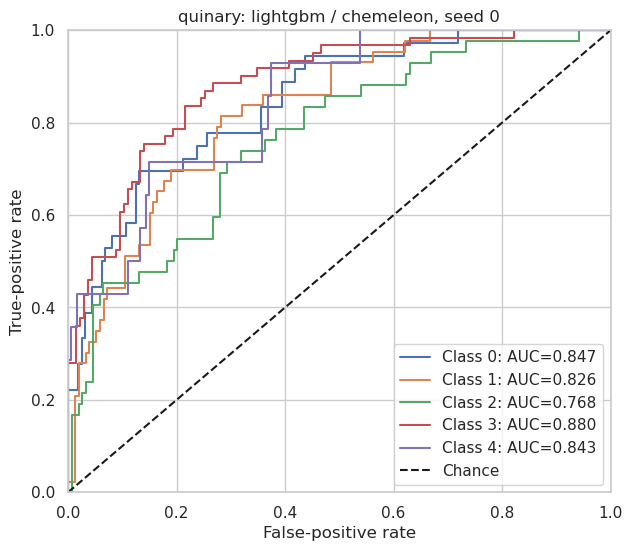

In [9]:
SELECTED_CLASSIFICATION = 'quinary'
selected_best = best_rows.loc[SELECTED_CLASSIFICATION]
SELECTED_MODEL = selected_best['model']
SELECTED_EMBEDDING = selected_best['embedding']

selected = runs.loc[(runs['classification'] == SELECTED_CLASSIFICATION) &
                    (runs['model'] == SELECTED_MODEL) &
                    (runs['embedding'] == SELECTED_EMBEDDING)].sort_values('seed')
run = selected.iloc[0]
artifact = joblib.load(Path(run['run_dir']) / 'model_and_results.pkl')
model = artifact['best_estimator']
test_idx = np.asarray(artifact['test_idx'], dtype=int)
y_test = np.asarray(artifact['y_test'])
x_test = np.load(embedding_paths[SELECTED_EMBEDDING], mmap_mode='r')[test_idx]
scores = model.predict_proba(x_test) if hasattr(model, 'predict_proba') else model.decision_function(x_test)
classes = np.asarray(model.classes_)

fig, axis = plt.subplots(figsize=(7, 6))
if len(classes) == 2:
    positive_scores = scores[:, 1] if np.ndim(scores) == 2 else scores
    fpr, tpr, _ = roc_curve(y_test, positive_scores, pos_label=classes[1])
    axis.plot(fpr, tpr, label=f'AUC = {auc(fpr, tpr):.3f}')
else:
    binary_targets = label_binarize(y_test, classes=classes)
    for column, label in enumerate(classes):
        fpr, tpr, _ = roc_curve(binary_targets[:, column], scores[:, column])
        axis.plot(fpr, tpr, label=f'Class {label}: AUC={auc(fpr, tpr):.3f}')
axis.plot([0, 1], [0, 1], 'k--', label='Chance')
axis.set(title=f'{SELECTED_CLASSIFICATION}: {SELECTED_MODEL} / {SELECTED_EMBEDDING}, seed {run.seed}',
         xlabel='False-positive rate', ylabel='True-positive rate', xlim=(0, 1), ylim=(0, 1))
axis.legend(loc='lower right'); plt.show()

## 6. Generalisation, runtime, difficult molecules, and hyperparameters

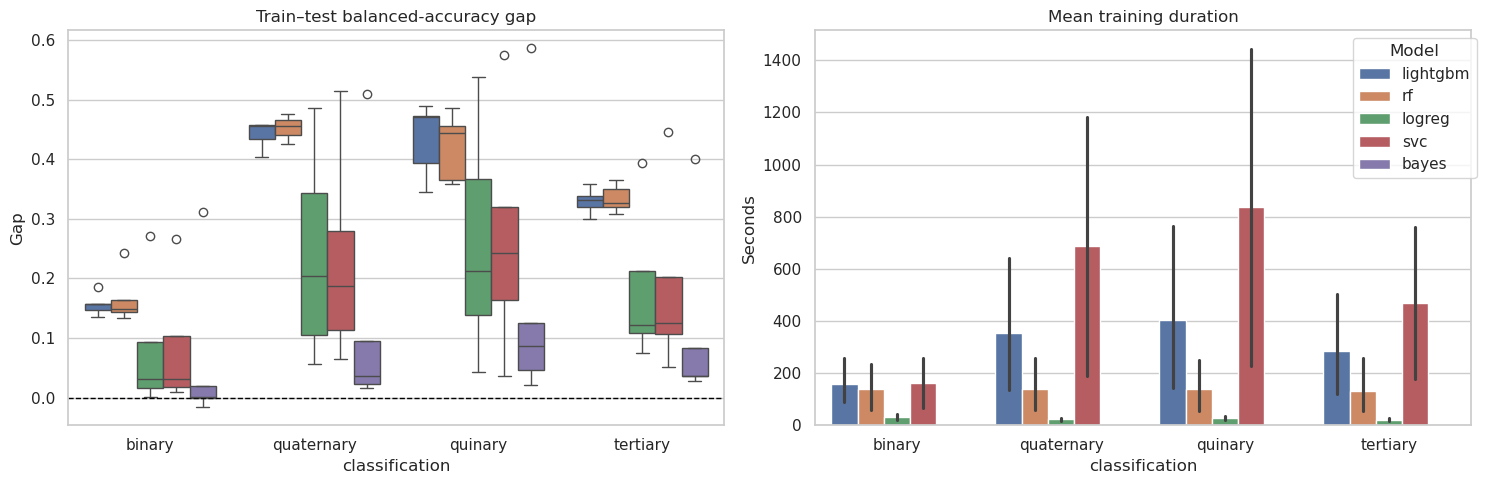

,classification,row_index,true_class,evaluations,errors,error_rate,SMILES,canonical_SMILES,Source,Exp IS (J)
0,binary,218,0,25,25,1.00,O=[N+]([O-])c1cc([N+](=O)[O-])c(-c2nnc(-c3c([N...,O=[N+]([O-])c1cc([N+](=O)[O-])c(-c2nnc(-c3c([N...,APPLETON,4.903325
1,binary,293,0,25,25,1.00,C=Cc1c([N+](=O)[O-])cc([N+](=O)[O-])cc1[N+](=O...,C=Cc1c([N+](=O)[O-])cc([N+](=O)[O-])cc1[N+](=O...,APPLETON,7.845320
2,binary,751,0,25,25,1.00,O=[N+](C1=C(C2=C([N+]([O-])=O)NN=C2[N+]([O-])=...,O=[N+]([O-])c1n[nH]c([N+](=O)[O-])c1-c1c([N+](...,QUAYLE,4.500000
3,binary,312,0,50,48,0.96,n6nc1nonc1c2nonc2c3nonc3nnc4nonc4c5nonc5c7nonc67,N1=Nc2nonc2-c2nonc2-c2nonc2N=Nc2nonc2-c2nonc2-...,MARRS,3.748500
4,binary,382,1,25,24,0.96,O=N(=O)OCCN(CCON(=O)=O)C(CON(=O)=O)(CON(=O)=O)...,O=[N+]([O-])OCCN(CCO[N+](=O)[O-])C(CO[N+](=O)[...,MARRS,8.000000
5,binary,408,1,25,24,0.96,O=C(OCC(N(=O)=O)(N(=O)=O)N(=O)=O)N(CCN(CC(N(=O...,O=C(OCC([N+](=O)[O-])([N+](=O)[O-])[N+](=O)[O-...,MARRS,10.000000
6,binary,509,0,25,24,0.96,N#N=c2c(n1nc(N(=O)=O)c(N)c1N(=O)=O)nnc2n3nc(N(...,[N-]=[N+]=C1C(n2nc([N+](=O)[O-])c(N)c2[N+](=O)...,MARRS,7.595000
7,binary,628,0,25,24,0.96,Nn1nc(N(=O)=O)c2c1c(N(=O)=O)nn2N,Nn1nc([N+](=O)[O-])c2c1c([N+](=O)[O-])nn2N,MARRS,7.000000
8,binary,630,0,25,24,0.96,NN/C(N)=C(N(=O)=O)/N(=O)=O,NNC(N)=C([N+](=O)[O-])[N+](=O)[O-],MARRS,6.000000
9,binary,735,1,25,24,0.96,O/C(C([N+]([O-])=O)([N+]([O-])=O)[N+]([O-])=O)...,O=[N+]([O-])/N=C(\O)C([N+](=O)[O-])([N+](=O)[O...,QUAYLE,19.000000


,classification,model,embedding,best_params,seeds
1,binary,bayes,chemeleon,"{""classifier__var_smoothing"": 3.16227766016837...",3
0,binary,bayes,chemeleon,"{""classifier__var_smoothing"": 1e-06}",2
2,binary,bayes,hq_descriptor,"{""classifier__var_smoothing"": 1e-12}",5
3,binary,bayes,maceoff_large,"{""classifier__var_smoothing"": 1e-12}",5
4,binary,bayes,molclr,"{""classifier__var_smoothing"": 1e-12}",5
5,binary,bayes,morgan_fps,"{""classifier__var_smoothing"": 1e-12}",5
6,binary,lightgbm,chemeleon,"{""classifier__class_weight"": ""balanced"", ""clas...",1
7,binary,lightgbm,chemeleon,"{""classifier__class_weight"": ""balanced"", ""clas...",1
8,binary,lightgbm,chemeleon,"{""classifier__class_weight"": ""balanced"", ""clas...",1
9,binary,lightgbm,chemeleon,"{""classifier__class_weight"": ""balanced"", ""clas...",1


In [10]:
plot_data = aggregate_results.copy()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=plot_data, x='classification', y='generalisation_gap_mean', hue='model', ax=axes[0])
axes[0].axhline(0, color='black', linestyle='--', linewidth=1)
axes[0].set(title='Train–test balanced-accuracy gap', ylabel='Gap')
sns.barplot(data=plot_data, x='classification', y='duration_seconds_mean', hue='model', ax=axes[1])
axes[1].set(title='Mean training duration', ylabel='Seconds')
axes[0].legend_.remove(); axes[1].legend(title='Model', bbox_to_anchor=(1.02, 1))
plt.tight_layout(); plt.show()

predictions, difficult_molecules = load_predictions(runs)
display(difficult_molecules.groupby('classification', group_keys=False).head(10))
hyperparameter_frequency = (runs.groupby(
    ['classification', 'model', 'embedding', 'best_params'], as_index=False
).agg(seeds=('seed', 'nunique')).sort_values(
    ['classification', 'model', 'embedding', 'seeds'], ascending=[True, True, True, False]
))
display(hyperparameter_frequency.head(30))

## 7. Export evaluation tables

In [11]:
export_tables(
    EXPORT_DIR, runs, aggregate_results, missing_runs, rejected_summaries,
    predictions, difficult_molecules, class_metrics,
)
class_metric_summary.to_csv(EXPORT_DIR / 'classification_per_class_aggregate.csv', index=False)
hyperparameter_frequency.to_csv(EXPORT_DIR / 'classification_hyperparameters.csv', index=False)
print(f'Exported evaluation tables to {EXPORT_DIR}')

Exported evaluation tables to /home/andre/fm-4-em/07_OUTPUTS/20260805/classification_evaluation
